Found 10000 files belonging to 2 classes.
Found 800 files belonging to 2 classes.
Found 992 files belonging to 2 classes.
['WithMask', 'WithoutMask']
----------
Before normalization:
Shape: (32, 128, 128, 3)
Min val: 0.0
Max val: 255.0

After normalization:
Shape: (32, 128, 128, 3)
Min val: 0.0
Max val: 1.0
----------
data has been augmented!


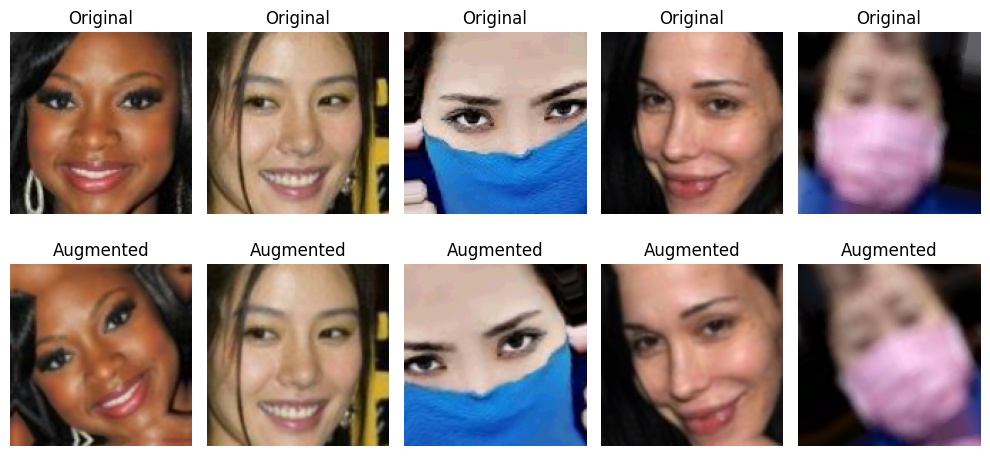

In [1]:
#copied preprocessing method form 02
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE_DIR = "../data"
#pls keep the data file at where yall put like in the 01 note, ty!
TRAIN_DIR = os.path.join(BASE_DIR, "Train")
VAL_DIR = os.path.join(BASE_DIR, "Validation")
TEST_DIR = os.path.join(BASE_DIR, "Test")

#i recommend going with image size 128 square and batch size 32 like many examples in class
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

#load dataset (and under the form of RGB right away too)
#we also will resize the img into IMG-_SIZE of 128 square too
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

#check number of img and class name
print(train_ds.class_names)
print('-'*10)

#normalize (make the RGB valuables from 0-255 range to 0-1 range)
#it's basically just a devide math, new pixel num = old num : 255
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds_nor = train_ds.map(lambda images, labels: (normalization_layer(images), labels))
val_ds_nor = val_ds.map(lambda images, labels: (normalization_layer(images), labels))
test_ds_nor = test_ds.map(lambda images, labels: (normalization_layer(images), labels))
#get a batch from pre-normalized set
raw_images, raw_labels = next(iter(train_ds))
#and one from normalized set
normalized_images, normalized_labels = next(iter(train_ds_nor))

print("Before normalization:")
print("Shape:", raw_images.shape)
print("Min val:", tf.reduce_min(raw_images).numpy())
print("Max val:", tf.reduce_max(raw_images).numpy())

print("\nAfter normalization:")
print("Shape:", normalized_images.shape)
print("Min val:", tf.reduce_min(normalized_images).numpy())
print("Max val:", tf.reduce_max(normalized_images).numpy())
print('-'*10)

#augmentation (but on normalized sets)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
], name="data_augmentation")

train_ds_augmented = train_ds_nor.map(lambda x, y: (data_augmentation(x, training=True), y))
print('data has been augmented!')

#check aug
images, labels = next(iter(train_ds_nor))
augmented_images = data_augmentation(
    images,
    training=True
)

plt.figure(figsize=(10, 5))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(augmented_images[i])
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [2]:
AUTOTUNE = tf.data.AUTOTUNE

#load img to ram right away once, save time and cpu power. 
#cuz cpu will load img in EVERY epochs without this. really sad if it really have to do so.

train_ds_final = train_ds_augmented.cache().prefetch(buffer_size=AUTOTUNE)

# val and test no need augmentation
val_ds_final = val_ds_nor.cache().prefetch(buffer_size=AUTOTUNE)
test_ds_final = test_ds_nor.cache().prefetch(buffer_size=AUTOTUNE)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization, 
    Dropout, Flatten, Dense
)

model = Sequential([
    #block 1
    Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)), #64x64
    Dropout(0.25),

    #block 2
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)), #32x32
    Dropout(0.25),

    #block 3
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)), #16x16
    Dropout(0.3),

    #block 4
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)), #8x8
    Dropout(0.3),

    #block 5
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)), #4x4
    Dropout(0.4),

    #classification head
    Flatten(),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    #final pred
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy', 
        tf.keras.metrics.Precision(name='precision'), 
        tf.keras.metrics.Recall(name='recall')
        ]
)

model.summary()

/home/ngocmai1411/venvs/facemask/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 16,699,201 (63.70 MB)

 Trainable params: 16,690,241 (63.67 MB)

 Non-trainable params: 8,960 (35.00 KB)

In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5,
    patience=3,
    min_lr=1e-6, 
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=10,
    restore_best_weights=True, 
)

EPOCHS = 50

history = model.fit(
    train_ds_final,
    validation_data=val_ds_final,
    epochs=EPOCHS,
    callbacks=[reduce_lr, early_stop],
    verbose=1
)

Epoch 1/50


/home/ngocmai1411/venvs/facemask/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791731290.784463    3778 service.cc:153] XLA service 0x772c1005e0d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791731290.784584    3778 service.cc:161]   StreamExecutor [0]: NVIDIA RTX A2000 8GB Laptop GPU, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791731291.048383    3778 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791731292.590647    3778 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791731292.941083    3778 dot_merger.cc:4

312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.9049 - loss: 0.2651 - precision: 0.8959 - recall: 0.9162

I0000 00:00:1791731411.979625    3779 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12848__.154


313/313 ━━━━━━━━━━━━━━━━━━━━ 169s 464ms/step - accuracy: 0.9051 - loss: 0.2649 - precision: 0.8961 - recall: 0.9164 - val_accuracy: 0.5587 - val_loss: 1.6764 - val_precision: 0.5313 - val_recall: 0.9975 - learning_rate: 0.0010
Epoch 2/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 168s 496ms/step - accuracy: 0.9414 - loss: 0.1639 - precision: 0.9343 - recall: 0.9496 - val_accuracy: 0.9737 - val_loss: 0.1038 - val_precision: 0.9611 - val_recall: 0.9875 - learning_rate: 0.0010
Epoch 3/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 184s 588ms/step - accuracy: 0.9539 - loss: 0.1365 - precision: 0.9484 - recall: 0.9600 - val_accuracy: 0.9787 - val_loss: 0.0786 - val_precision: 0.9728 - val_recall: 0.9850 - learning_rate: 0.0010
Epoch 4/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 177s 565ms/step - accuracy: 0.9579 - loss: 0.1191 - precision: 0.9531 - recall: 0.9632 - val_accuracy: 0.9550 - val_loss: 0.1240 - val_precision: 0.9715 - val_recall: 0.9375 - learning_rate: 0.0010
Epoch 5/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 128s 408ms/step - a

In [ ]:
#save the trained model to local
model.save("../model/mask_complex_CNN_01.keras")
print("Model successfully saved to '../model/mask_complex_CNN_01.keras'!")

Model successfully saved to '../model/mask_complex_CNN_01.keras'!


Evaluating loaded model on test Set...
31/31 ━━━━━━━━━━━━━━━━━━━━ 97s 3s/step - accuracy: 0.9940 - loss: 0.0406 - precision: 1.0000 - recall: 0.9882
loss: 0.0406
compile_metrics: 0.9940
31/31 ━━━━━━━━━━━━━━━━━━━━ 28s 888ms/step
Calculated F1-Score: 0.9941

Confusion Matrix:
[[483   0]
 [  6 503]]
Classification Report:
              precision    recall  f1-score   support

    WithMask       0.99      1.00      0.99       483
 WithoutMask       1.00      0.99      0.99       509

    accuracy                           0.99       992
   macro avg       0.99      0.99      0.99       992
weighted avg       0.99      0.99      0.99       992



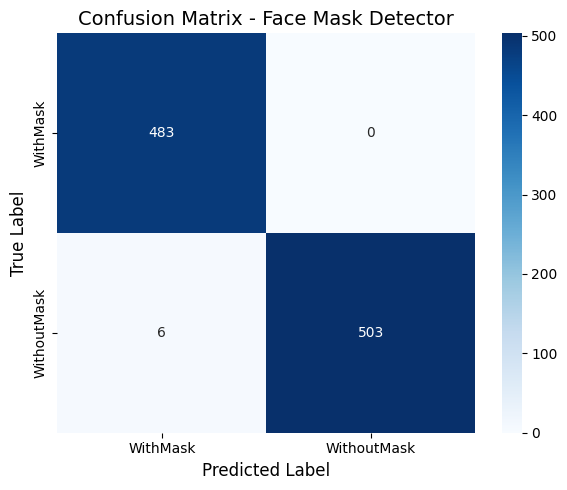

In [ ]:
from sklearn.metrics import confusion_matrix, f1_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model


loaded_model = load_model(
    "../model/mask_complex_CNN_01.keras"
)

print("Evaluating loaded model on test Set...")
test_results = loaded_model.evaluate(test_ds_final, verbose=1)

for name, value in zip(loaded_model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")



y_pred_probs = loaded_model.predict(test_ds_final, verbose=1)
y_true = np.concatenate([labels for _, labels in test_ds_final], axis=0)

y_true = y_true.astype(int).flatten()
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

f1 = f1_score(y_true, y_pred)
conf_matrix = confusion_matrix(y_true, y_pred)

print(f"Calculated F1-Score: {f1:.4f}\n")
print("Confusion Matrix:")
print(conf_matrix)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=['WithMask', 'WithoutMask']))

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['WithMask', 'WithoutMask'], 
            yticklabels=['WithMask', 'WithoutMask'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Face Mask Detector', fontsize=14)
plt.tight_layout()
plt.show()